# 05 · Análises do piloto (QP1 a QP4)

**Objetivo.** Reunir as análises do piloto nas quatro frentes que nomeiam os arquivos de saída: trajetória das métricas ao redor da adoção (QP1), avisos novos por grupo de arquivos (QP2), intensidade de uso de agentes e avisos novos por autor (QP3) e sobrevivência dos avisos introduzidos (QP4).

- **Lê:** `../out/piloto.csv`, `../out/atribuicao_resumo.csv`, `../out/<projeto>/arquivos_mensais.parquet`, `../out/<projeto>/commits_atribuidos.csv`, `../repos/<projeto>/` (via `git log`), `../out/alteracoes.csv` e `../out/avisos_introduzidos.csv`
- **Grava:** `../out/figs/qp1_trajetorias.png`, `../out/qp1_faixas.csv`, `../out/qp2_taxas.csv`, `../out/qp2_por_projeto.csv`, `../out/qp3_intensidade.csv`, `../out/qp3_por_agente.csv`, `../out/figs/qp4_sobrevivencia.png` e `../out/qp4_resumo.csv`

Nos caminhos, `<projeto>` é o nome do repositório com `/` trocado por `__`.

**O que esta célula faz.** Carrega as medições mensais de cada projeto (notebook 03) e a data de adoção, define `rel` como o mês relativo à adoção (`rel = 0` é o mês da adoção) e monta o painel (projeto, mês) somando SLOC (linhas de código sem brancos nem comentários), avisos do Ruff, avisos de complexidade, SATD (self-admitted technical debt: comentários com TODO, FIXME, HACK ou XXX) e complexidade. Calcula então as densidades por KLOC (mil linhas de código, medidas em SLOC) e a complexidade média por função, e imprime o número de projetos e de meses por projeto como conferência.

In [2]:
import os, re, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

os.makedirs('../out/figs', exist_ok=True)
piloto = pd.read_csv('../out/piloto.csv')
REPOS = list(piloto.full_name)
resumo = pd.read_csv('../out/atribuicao_resumo.csv').set_index('projeto')
adocao = pd.to_datetime(resumo.adocao, utc=True)            # primeiro commit de agente, por projeto
chave = lambda n: n.replace('/', '__')
curto = lambda n: n.split('/')[1]

# arquivos por mês (Etapa 4) com o mês relativo à adoção: rel = 0 é o mês da adoção
F = []
for n in REPOS:
    f = pd.read_parquet(f'../out/{chave(n)}/arquivos_mensais.parquet')
    f['repo'] = n
    a = adocao[n]
    f['rel'] = (f.mes.str[:4].astype(int) * 12 + f.mes.str[5:].astype(int)) - (a.year * 12 + a.month)
    F.append(f)
F = pd.concat(F, ignore_index=True)

# painel (projeto, mês): somas e densidades
P = F.groupby(['repo', 'rel']).agg(sloc=('sloc', 'sum'), avisos=('avisos', 'sum'), compl=('avisos_complexidade', 'sum'),
                                   satd=('satd', 'sum'), cc=('cc_total', 'sum'), nf=('n_funcoes', 'sum')).reset_index()
P['avisos_kloc'] = P.avisos / P.sloc * 1000
P['compl_kloc'] = P.compl / P.sloc * 1000
P['satd_kloc'] = P.satd / P.sloc * 1000
P['cc_func'] = P.cc / P.nf.replace(0, np.nan)
METRICAS = {'avisos_kloc': 'Avisos por KLOC', 'cc_func': 'Complexidade média por função', 'satd_kloc': 'SATD por KLOC'}
print('Projetos:', len(REPOS), '| meses por projeto:', P.groupby('repo').size().to_dict())

Projetos: 5 | meses por projeto: {'NewFuture/DDNS': 27, 'airbytehq/PyAirbyte': 33, 'econ-ark/HARK': 29, 'lidofinance/diffyscan': 29, 'numbagg/numbagg': 28}


**O que isto mostra.** O painel tem 5 projetos, com 27 meses em DDNS, 33 em PyAirbyte, 29 em HARK, 29 em diffyscan e 28 em numbagg. Esses números coincidem com os meses por projeto medidos no notebook 03, o que confirma que o painel tem uma linha por mês medido de cada projeto.

**O que esta célula faz.** Para cada métrica (avisos por KLOC, complexidade média por função e SATD por KLOC) e projeto, compara a média mensal de quatro faixas de meses relativos à adoção (-6 a -2, 0 a 5, 6 a 11 e 12 a 15) com o valor do mês -1, em variação percentual, e grava `qp1_faixas.csv`. Desenha, em três painéis, a trajetória mensal de cada projeto dividida pelo valor do mês -1 (razão 1 = igual ao mês -1); projetos com valor de base zero ficam sem razão.

,métrica,projeto,mês -1,-6 a -2,0 a 5,6 a 11,12 a 15
0,Avisos por KLOC,numbagg,14.80,-0%,-4%,-4%,-7%
1,Avisos por KLOC,HARK,27.98,-1%,+3%,-3%,-11%
2,Avisos por KLOC,DDNS,14.48,+34%,-13%,-13%,-18%
3,Avisos por KLOC,diffyscan,42.42,+2%,-35%,-54%,-67%
4,Avisos por KLOC,PyAirbyte,7.45,-4%,-1%,-5%,-10%
5,Complexidade média por função,numbagg,3.27,+1%,+6%,+5%,+4%
6,Complexidade média por função,HARK,2.42,-0%,+6%,+2%,-3%
7,Complexidade média por função,DDNS,4.07,-3%,-48%,-48%,-43%
8,Complexidade média por função,diffyscan,3.21,+1%,+1%,-0%,-0%
9,Complexidade média por função,PyAirbyte,2.74,-1%,+0%,+4%,+8%


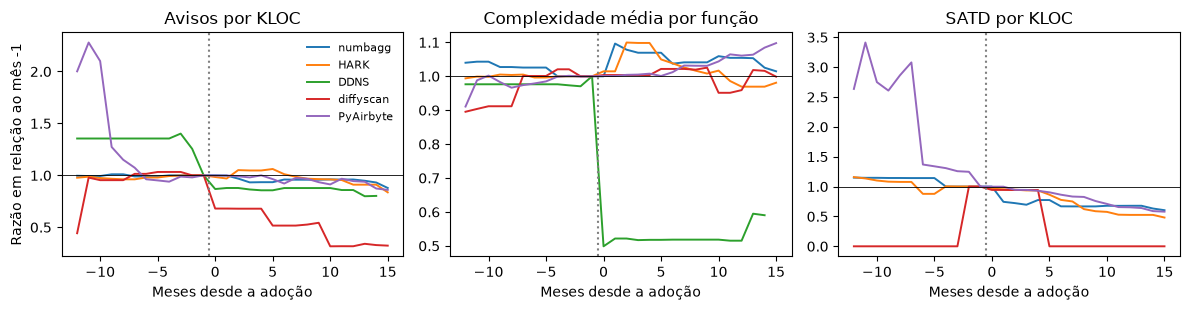

In [3]:
base = P[P.rel == -1].set_index('repo')
faixas = [(-6, -2, '-6 a -2'), (0, 5, '0 a 5'), (6, 11, '6 a 11'), (12, 15, '12 a 15')]
linhas = []
for y, nome in METRICAS.items():
    for repo in REPOS:
        d = P[P.repo == repo]
        linha = {'métrica': nome, 'projeto': curto(repo), 'mês -1': round(base.loc[repo, y], 2)}
        for lo, hi, rot in faixas:
            m = d[(d.rel >= lo) & (d.rel <= hi)][y].mean()
            linha[rot] = f'{(m / base.loc[repo, y] - 1) * 100:+.0f}%' if pd.notna(m) and base.loc[repo, y] > 0 else '-'
        linhas.append(linha)
qp1 = pd.DataFrame(linhas)
qp1.to_csv('../out/qp1_faixas.csv', index=False)

fig, eixos = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True)
cor = dict(zip(REPOS, plt.rcParams['axes.prop_cycle'].by_key()['color']))   # uma cor fixa por projeto
for ax, (y, nome) in zip(eixos, METRICAS.items()):
    for repo in REPOS:
        d = P[(P.repo == repo) & (P.rel >= -12) & (P.rel <= 15)]
        if base.loc[repo, y] > 0:                      # sem valor de base (zero), a razão não existe
            ax.plot(d.rel, d[y] / base.loc[repo, y], label=curto(repo), lw=1.4, color=cor[repo])
    ax.axvline(-0.5, color='gray', ls=':'); ax.axhline(1, color='black', lw=0.6)
    ax.set_title(nome); ax.set_xlabel('Meses desde a adoção')
eixos[0].set_ylabel('Razão em relação ao mês -1'); eixos[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig('../out/figs/qp1_trajetorias.png', dpi=200)
qp1

**O que isto mostra.** Na faixa 12 a 15, os avisos por KLOC caem nos cinco projetos (numbagg -7%, HARK -11%, DDNS -18%, diffyscan -67%, PyAirbyte -10%) e o SATD por KLOC cai nos quatro com valor de base (numbagg -35%, HARK -49%, diffyscan -100%, PyAirbyte -38%); DDNS tem SATD de 0.00 no mês -1 e fica sem razão ("-"). A complexidade média por função varia pouco em quatro projetos (de -3% a +8% na faixa 12 a 15), mas cai -48% em DDNS já na faixa 0 a 5 e fica em -43% na faixa 12 a 15; no gráfico a linha de DDNS cai de forma abrupta no mês da adoção, e a saída não permite dizer o motivo. Parte das variações já aparece antes da adoção: na faixa -6 a -2, os avisos por KLOC de DDNS estão +34% e o SATD de PyAirbyte +30% em relação ao mês -1, e o gráfico mostra a razão de avisos de PyAirbyte em torno de 2 nos primeiros meses (leitura visual), de modo que tendências anteriores dificultam atribuir as quedas à adoção. Com 5 projetos, sem grupo de comparação e com um único mês como base, valores pequenos de base (por exemplo, 0.62 de SATD por KLOC em diffyscan, onde -100% significa nenhum comentário SATD nas faixas 6 a 11 e 12 a 15) produzem variações percentuais grandes; os resultados descrevem a amostra e não indicam efeito dos agentes.

**O que esta célula faz.** Compara, arquivo a arquivo, o último mês medido com o mês -1 e classifica os arquivos em grupos: pré-existentes alterados só por humanos (H), pré-existentes tocados por agente (A), novos criados por humano ou por agente e uma linha de base pré-adoção (arquivos que mudaram entre o mês -12 e o mês -1). Usa o histórico first-parent (o branch principal, seguindo só o primeiro pai de cada merge) para saber quem tocou cada arquivo e o blob (versão do conteúdo do arquivo) para detectar quais arquivos mudaram na linha de base. Para cada grupo calcula avisos novos e complexidade nova por KLOC adicionada (soma da variação dividida pela soma das linhas adicionadas, só nos arquivos que cresceram) e imprime uma checagem sobre os arquivos sem toque identificado (grupo U).

In [4]:
def toques(repo_dir, desde):
    """Arquivos .py alterados em cada commit do first-parent depois de `desde` (git log --raw -M)."""
    r = subprocess.run(['git', '-C', repo_dir, 'log', '--first-parent', '-M', '--raw', '--no-abbrev', '--format=%x1e%H',
                        f'{desde}..HEAD' if desde else 'HEAD'], capture_output=True)
    saida = {}
    for rec in r.stdout.decode('utf-8', 'replace').split('\x1e')[1:]:
        linhas = rec.strip().splitlines()
        caminhos = []
        for l in linhas[1:]:
            if l.startswith(':'):
                meta, *c = l.split('\t')
                if meta.split()[4][0] != 'D':
                    caminhos.append(c[-1])
        saida[linhas[0].strip()] = caminhos
    return saida

EXCL = re.compile(r'(^|/)(\.venv|venv|env|site-packages|node_modules|vendor|third_party|build|dist|\.tox)/')
linhas, intensidade = [], {}
for repo in REPOS:
    h = pd.read_csv(f'../out/{chave(repo)}/commits_atribuidos.csv')
    h['data'] = pd.to_datetime(h.data, utc=True)
    h = h.sort_values('data').reset_index(drop=True)
    antes = h[h.data < adocao[repo]]
    mud = toques(f'../repos/{chave(repo)}', antes.iloc[-1].sha if len(antes) else None)
    pos = h[h.data >= adocao[repo]]
    ag_path, hu_path, n_py, n_ag = {}, {}, 0, 0
    for c in pos.itertuples():
        py = [p for p in mud.get(c.sha, []) if p.endswith('.py') and not EXCL.search(p)]
        if not py:
            continue
        n_py += 1; n_ag += int(c.is_agente)
        for p in py:
            (ag_path if c.is_agente else hu_path).setdefault(p, c.data)
    intensidade[repo] = dict(commits_py=n_py, commits_agente=n_ag, intensidade=round(n_ag / n_py, 3) if n_py else np.nan)

    f = F[F.repo == repo]
    pre = f[f.rel == -1].set_index('arquivo')
    ult = f.sort_values('rel').groupby('arquivo').tail(1).set_index('arquivo')
    for caminho, l in ult.iterrows():
        ag, hu = caminho in ag_path, caminho in hu_path
        if caminho in pre.index:
            b = pre.loc[caminho]
            grupo = 'A' if ag else ('H' if hu else 'U')
            tipo = 'pre-existente'
            d = dict(d_sloc=l.sloc - b.sloc, d_avisos=l.avisos - b.avisos, d_cc=l.cc_total - b.cc_total)
        elif l.rel >= 0:
            grupo = 'A' if (ag and (not hu or ag_path[caminho] <= hu_path[caminho])) else 'H'
            tipo = 'novo'
            d = dict(d_sloc=l.sloc, d_avisos=l.avisos, d_cc=l.cc_total)
        else:
            continue
        linhas.append(dict(repo=repo, arquivo=caminho, tipo=tipo, grupo=grupo, **d))
Q2 = pd.DataFrame(linhas)

# linha de base pré-adoção: arquivos que existiam em rel=-12 e -1 e mudaram (só humanos, por definição)
pre_l = []
for repo in REPOS:
    f = F[F.repo == repo]
    ini = f[f.rel == f.rel.min()].set_index('arquivo'); fim = f[f.rel == -1].set_index('arquivo')
    comum = ini.index.intersection(fim.index)
    mud_ = comum[(fim.loc[comum, 'blob'] != ini.loc[comum, 'blob']).values]
    d = (fim.loc[mud_, ['sloc', 'avisos', 'cc_total']] - ini.loc[mud_, ['sloc', 'avisos', 'cc_total']])
    d.columns = ['d_sloc', 'd_avisos', 'd_cc']; d['repo'] = repo; d['grupo'] = 'pre'
    pre_l.append(d)
PRE = pd.concat(pre_l)

def taxa(df, col):
    """variação por KLOC adicionada: soma da variação / soma das linhas adicionadas (só arquivos que cresceram)."""
    d = df[df.d_sloc > 0]
    return round(d[col].sum() / d.d_sloc.sum() * 1000, 1) if d.d_sloc.sum() else np.nan

grupos = [('Pré-adoção: alterados', PRE), ('Pós: existentes, só humanos (H)', Q2[(Q2.tipo == 'pre-existente') & (Q2.grupo == 'H')]),
          ('Pós: existentes, tocados por agente (A)', Q2[(Q2.tipo == 'pre-existente') & (Q2.grupo == 'A')]),
          ('Pós: novos, criados por humanos', Q2[(Q2.tipo == 'novo') & (Q2.grupo == 'H')]),
          ('Pós: novos, criados por agente', Q2[(Q2.tipo == 'novo') & (Q2.grupo == 'A')])]
qp2 = pd.DataFrame([{'grupo': nome, 'arquivos': len(d), 'KLOC adicionada': round(d[d.d_sloc > 0].d_sloc.sum() / 1000, 2),
                     'avisos novos por KLOC': taxa(d, 'd_avisos'), 'complexidade nova por KLOC': taxa(d, 'd_cc')}
                    for nome, d in grupos])
por_proj = pd.DataFrame({curto(r): {nome: taxa(d[d.repo == r], 'd_avisos') for nome, d in grupos} for r in REPOS})
print('Sanidade: soma da variação de avisos nos arquivos U (deve ser perto de 0):',
      Q2[Q2.grupo == 'U'].d_avisos.sum())
qp2.to_csv('../out/qp2_taxas.csv', index=False); por_proj.to_csv('../out/qp2_por_projeto.csv')
display(qp2); display(por_proj)

Sanidade: soma da variação de avisos nos arquivos U (deve ser perto de 0): 0


,grupo,arquivos,KLOC adicionada,avisos novos por KLOC,complexidade nova por KLOC
0,Pré-adoção: alterados,79,1.52,36.7,150.8
1,"Pós: existentes, só humanos (H)",71,1.75,0.6,137.4
2,"Pós: existentes, tocados por agente (A)",128,8.36,8.1,184.4
3,"Pós: novos, criados por humanos",168,42.96,13.1,199.7
4,"Pós: novos, criados por agente",156,39.38,5.0,166.2


,numbagg,HARK,DDNS,diffyscan,PyAirbyte
Pré-adoção: alterados,0.0,50.2,NaN,NaN,-5.9
"Pós: existentes, só humanos (H)",0.0,5.6,NaN,-8.7,0.0
"Pós: existentes, tocados por agente (A)",13.2,-8.8,21.5,15.9,8.9
"Pós: novos, criados por humanos",0.0,20.1,9.9,5.1,4.6
"Pós: novos, criados por agente",10.3,NaN,10.4,5.9,3.6


**O que isto mostra.** No agregado, os avisos novos por KLOC adicionada são 36.7 nos arquivos alterados antes da adoção (79 arquivos, 1.52 KLOC), 0.6 nos pré-existentes só humanos (71 arquivos, 1.75 KLOC), 8.1 nos pré-existentes tocados por agente (128 arquivos, 8.36 KLOC), 13.1 nos novos criados por humanos (168 arquivos, 42.96 KLOC) e 5.0 nos novos criados por agente (156 arquivos, 39.38 KLOC), enquanto a complexidade nova por KLOC fica entre 137.4 e 199.7 sem ordem evidente. As taxas dos dois primeiros grupos vêm de poucas linhas adicionadas (1.52 e 1.75 KLOC) e são instáveis: por projeto, o grupo pré-adoção vai de -5.9 (PyAirbyte) a 50.2 (HARK), com NaN (nenhum arquivo do grupo cresceu) em DDNS e diffyscan. A ordem entre arquivos novos de agente e de humanos no agregado (5.0 contra 13.1) não se repete em todos os projetos (numbagg 10.3 contra 0.0, DDNS 10.4 contra 9.9, diffyscan 5.9 contra 5.1, PyAirbyte 3.6 contra 4.6, HARK sem valor para agente), e como o agregado depende do peso de cada projeto, que a saída não detalha, e os grupos não são aleatórios (um arquivo tocado por agente pode ter sido tocado também por humanos), as diferenças não indicam efeito de quem escreveu o código. Verificação: a soma da variação de avisos nos arquivos pré-existentes sem toque identificado (grupo U) é 0, como esperado, já que arquivos que nenhum commit alterou não mudam de avisos.

**O que esta célula faz.** Monta, por projeto, a intensidade de agente (commits de agente divididos pelos commits que alteram `.py` depois da adoção) e a variação percentual de cada métrica entre o mês -1 e a média dos meses 9 a 12, sem calcular correlação por haver só 5 projetos. Depois junta `alteracoes.csv` e `avisos_introduzidos.csv` e calcula, por ator (cada agente ou humano), os avisos novos por KLOC adicionada, em que a KLOC é a soma dos aumentos de SLOC por alteração (reduções contam zero).

In [5]:
I = pd.DataFrame(intensidade).T
for y, nome in METRICAS.items():
    fim = P[(P.rel >= 9) & (P.rel <= 12)].groupby('repo')[y].mean()
    I[f'var % {y}'] = ((fim / base[y] - 1) * 100).round(0)
I['agente principal'] = resumo.agente_principal
I.index = [curto(r) for r in I.index]
I.to_csv('../out/qp3_intensidade.csv')
display(I)   # com 5 projetos, observe os pares lado a lado; não calcule correlação de Spearman

A = pd.read_csv('../out/alteracoes.csv'); N = pd.read_csv('../out/avisos_introduzidos.csv')
novos = N.groupby(['repo', 'sha', 'caminho']).size().rename('novos').reset_index()
A = A.merge(novos, on=['repo', 'sha', 'caminho'], how='left').fillna({'novos': 0})
A['ator'] = np.where(A.autor_agente, A.agente, 'Humano')
A['d_sloc'] = (A.sloc_depois - A.sloc_antes).clip(lower=0)
qp3 = A.groupby('ator').agg(alteracoes=('novos', 'size'), avisos_novos=('novos', 'sum'), kloc_adicionada=('d_sloc', lambda s: s.sum() / 1000))
qp3['avisos novos por KLOC'] = (qp3.avisos_novos / qp3.kloc_adicionada).round(1)
qp3.to_csv('../out/qp3_por_agente.csv')
qp3

,commits_py,commits_agente,intensidade,var % avisos_kloc,var % cc_func,var % satd_kloc,agente principal
numbagg,88.0,25.0,0.284,-4.0,5.0,-32.0,Claude_Code
HARK,159.0,14.0,0.088,-5.0,-0.0,-45.0,OpenAI_Codex
DDNS,71.0,38.0,0.535,-13.0,-48.0,NaN,Copilot
diffyscan,36.0,4.0,0.111,-63.0,-3.0,-100.0,OpenAI_Codex
PyAirbyte,217.0,178.0,0.820,-6.0,5.0,-31.0,Devin


,alteracoes,avisos_novos,kloc_adicionada,avisos novos por KLOC
ator,,,,
Claude_Code,86,35.0,2.904,12.1
Copilot,279,122.0,8.433,14.5
Cursor,6,0.0,0.015,0.0
Devin,776,162.0,34.892,4.6
Humano,443,235.0,17.770,13.2
OpenAI_Codex,19,5.0,0.108,46.3


**O que isto mostra.** A intensidade vai de 0.088 em HARK a 0.820 em PyAirbyte (numbagg 0.284, DDNS 0.535, diffyscan 0.111), e a variação dos avisos por KLOC entre o mês -1 e os meses 9 a 12 é negativa nos cinco projetos (de -4% a -63%). Lado a lado, os pares não mostram ordenação clara: diffyscan tem a maior queda (-63%) com intensidade 0.111 (4 commits de agente) e PyAirbyte, de maior intensidade, tem -6%; com 5 pontos não se calcula correlação. Por ator, os avisos novos por KLOC adicionada são Devin 4.6 (34.892 KLOC), Humano 13.2 (17.770 KLOC), Claude_Code 12.1 (2.904 KLOC), Copilot 14.5 (8.433 KLOC), Cursor 0.0 (0.015 KLOC) e OpenAI_Codex 46.3 (0.108 KLOC). Os valores de OpenAI_Codex (5 avisos em 19 alterações) e Cursor (0 em 6) vêm de poucas linhas e não são comparáveis com os demais; além disso, o agente principal difere por projeto (tabela acima), de modo que diferenças entre agentes se confundem com diferenças entre projetos, e a linha Humano é a amostra de commits humanos do notebook 04.

**O que esta célula faz.** Estima, com Kaplan–Meier (estimador da fração de itens que ainda "sobrevivem" ao longo do tempo; aqui, a fração de avisos ainda presentes t dias depois da introdução, tratando como censurados os avisos não removidos até a data da coleta), a sobrevivência dos avisos introduzidos por agentes e por humanos, e aplica o teste log-rank. A primeira tabela resume número de avisos, removidos, sobrevivência em 90 e 365 dias (S(t)), mediana de dias até a remoção, parcela corrigida (o resto é arquivo apagado) e parcela removida por commit de agente. A segunda conta os avisos por família de regra do Ruff (prefixo do código) e tipo de autor, mostrando as 8 famílias com mais avisos de agentes.

Coleta em 2026-10-27
Log-rank (valor-p NÃO interpretável com 5 projetos, só para conferir que roda): 0.1544


,grupo,avisos,projetos,removidos,ainda presentes,S(90 dias),S(365 dias),mediana de dias (removidos),% corrigidos (resto: arquivo apagado),% removidos por agente
0,Introduzidos por agentes,324,5,83,74%,0.78,0.74,7.0,90%,64%
1,Introduzidos por humanos,235,5,45,81%,0.81,0.77,12.0,100%,31%


autor_agente,agente,humano
familia,,
PLR,178,84
SIM,67,49
C,25,18
ERA,22,8
PLW,15,7
B,9,50
F,7,2
E,1,11


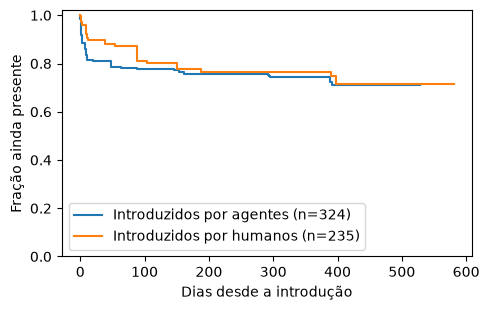

In [6]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

N['data'] = pd.to_datetime(N.data, utc=True)
N['data_remocao'] = pd.to_datetime(N.data_remocao, utc=True)
COLETA = max(pd.read_csv(f'../out/{chave(r)}/commits_atribuidos.csv', usecols=['data']).data.pipe(pd.to_datetime, utc=True).max()
             for r in REPOS)                                  # data da coleta: o último commit dos clones
N['dias'] = ((N.data_remocao.fillna(COLETA) - N.data).dt.total_seconds() / 86400).clip(lower=0)
N['removido'] = N.data_remocao.notna().astype(int)
N['familia'] = N.regra.str.extract(r'^([A-Z]+)')[0]
print('Coleta em', COLETA.date())

fig, ax = plt.subplots(figsize=(5, 3.2))
linhas = []
for rot, g in [('Introduzidos por agentes', N[N.autor_agente]), ('Introduzidos por humanos', N[~N.autor_agente])]:
    km = KaplanMeierFitter().fit(g.dias, g.removido, label=f'{rot} (n={len(g)})')
    km.plot_survival_function(ax=ax, ci_show=False)
    rem = g[g.removido == 1]
    linhas.append({'grupo': rot, 'avisos': len(g), 'projetos': g.repo.nunique(), 'removidos': len(rem),
                   'ainda presentes': f'{(1 - g.removido.mean()) * 100:.0f}%',
                   'S(90 dias)': round(float(km.predict(90)), 2), 'S(365 dias)': round(float(km.predict(365)), 2),
                   'mediana de dias (removidos)': round(rem.dias.median(), 0) if len(rem) else None,
                   '% corrigidos (resto: arquivo apagado)': f'{(rem.como == "aviso corrigido").mean() * 100:.0f}%' if len(rem) else None,
                   '% removidos por agente': f'{rem.removido_por_agente.astype(float).mean() * 100:.0f}%' if len(rem) else None})
ax.set_xlabel('Dias desde a introdução'); ax.set_ylabel('Fração ainda presente'); ax.set_ylim(0, 1.02)
fig.tight_layout(); fig.savefig('../out/figs/qp4_sobrevivencia.png', dpi=200)
qp4 = pd.DataFrame(linhas)
qp4.to_csv('../out/qp4_resumo.csv', index=False)
a, h = N[N.autor_agente], N[~N.autor_agente]
print('Log-rank (valor-p NÃO interpretável com 5 projetos, só para conferir que roda):',
      round(logrank_test(a.dias, h.dias, a.removido, h.removido).p_value, 4))
display(qp4)
display(pd.crosstab(N.familia, N.autor_agente.map({True: 'agente', False: 'humano'})).sort_values('agente', ascending=False).head(8))

**O que isto mostra.** Foram rastreados 324 avisos introduzidos por agentes e 235 por humanos, nos 5 projetos; até a coleta (2026-10-27), 74% dos de agentes e 81% dos humanos ainda estavam presentes (83 e 45 removidos), com S(90 dias) = 0.78 contra 0.81 e S(365 dias) = 0.74 contra 0.77. Entre os removidos, a mediana foi de 7.0 dias para agentes e 12.0 para humanos, 90% e 100% foram corrigidos (o resto, por arquivo apagado) e 64% e 31% foram removidos por commits de agente, parcelas que podem refletir apenas a distribuição de commits de agente entre os projetos. No gráfico, as duas curvas de Kaplan–Meier caem rápido nos primeiros dias e se estabilizam próximas entre si, entre cerca de 0.7 e 0.8 (leitura visual), e o log-rank retornou p = 0.1544, valor que, como o próprio código indica, não deve ser interpretado com 5 projetos. Na tabela por família (contagens brutas, só as 8 primeiras linhas), PLR é a mais frequente nos dois grupos (178 de agente e 84 de humano) e B tem mais ocorrências humanas (50) que de agente (9); a coluna de agentes soma 324, igual ao n da curva, e a de humanos soma 229 de 235, com os 6 restantes em famílias fora das linhas exibidas.

## Limitações do piloto

- **Amostra de 5 projetos.** Trata-se de um piloto: valores-p (como o do log-rank, 0.1544) e razões entre grupos não devem ser interpretados, e os resultados descrevem a amostra, sem inferência causal.
- **Um projeto domina os totais.** PyAirbyte concentra 871 das alterações rastreadas (notebook 04) e Devin, agente principal desse projeto, soma 34.892 KLOC adicionada; HARK tem a maior contagem bruta de avisos medidos (9376, notebook 03). Taxas agregadas refletem sobretudo esses projetos.
- **Medições só em Python.** Apenas arquivos `.py` entram nas medições; outras linguagens e arquivos não Python ficam de fora.
- **Avisos do Ruff são uma aproximação de qualidade.** Usam um conjunto fixo de regras, e o número de avisos, a complexidade e o SATD são indicadores indiretos, não medidas de defeitos ou de manutenibilidade.
- **Atribuição a agentes sem validação manual.** A atribuição combina PRs do AIDev e assinaturas textuais; a assinatura não foi validada manualmente, e commits de agentes sem marca, ou código de agentes editado por humanos, podem estar classificados de forma imprecisa.